## Carregando os dados

In [1]:
# importando bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.plotting import scatter_matrix

#importando o arquivo
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.plotting import scatter_matrix

df = pd.read_csv(Path("iris2.csv"), sep=",")
df.head()


,id_planta,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala,cidade_origem,classe
0,0,5.1,3.5,1.4,0.2,São Paulo,Iris-setosa
1,1,4.9,3.0,1.4,0.2,Sorocaba,Iris-setosa
2,2,4.7,3.2,1.3,0.2,São Paulo,Iris-setosa
3,3,4.6,3.1,1.5,0.2,Sorocaba,Iris-setosa
4,4,5.0,3.6,1.4,0.2,São Paulo,Iris-setosa


## Pré-processamento: eliminação de atributos irrelevantes

In [2]:
# remove as colunas id_planta e cidade_origem
df = df.drop(columns=['id_planta','cidade_origem'])

# imprime o dataframe
display(df.head(n=10))

,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala,classe
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
5,5.4,3.9,1.7,0.4,Iris-setosa
6,4.6,3.4,1.4,0.3,Iris-setosa
7,5.0,3.4,1.5,0.2,Iris-setosa
8,4.4,2.9,1.4,0.2,Iris-setosa
9,4.9,3.1,1.5,0.1,Iris-setosa


## Pré-processamento: tratamento de atributos com valores ausentes

In [3]:
# índices das linhas que contém valores NaN
idxRowNan = pd.isnull(df).any(axis=1).to_numpy().nonzero()

# imprime apenas as linhas com valoes ausentes
display(df.iloc[idxRowNan])

,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala,classe
23,5.1,NaN,1.7,0.5,Iris-setosa
24,4.8,NaN,1.9,0.2,Iris-setosa
30,4.8,3.1,NaN,0.2,Iris-setosa


In [4]:
def trataFaltantes(df):
    '''
    Substitui os valores faltantes pela média dos outros valores do mesmo atributo
    de amostras que sejam da mesma classe
    '''

    # seleciona apenas as linhas da base de dados onde a coluna largura_sepala não contém valores nulos
    notNull_ls = df.loc[ ~pd.isnull(df['largura_sepala']), :]
    notNull_cp = df.loc[ ~pd.isnull(df['comprimento_petala']), :]

    # calcula a media dos valores do atributo largura_sepala que não são nulos e que são da classe Iris-setosa
    media_ls = notNull_ls[ notNull_ls['classe']=='Iris-setosa' ]['largura_sepala'].mean()
    media_cp = notNull_cp[ notNull_cp['classe']=='Iris-setosa' ]['comprimento_petala'].mean()

    # substitui os valores nulos pela média
    df.loc[ pd.isnull(df['largura_sepala']), 'largura_sepala'] = media_ls
    df.loc[ pd.isnull(df['comprimento_petala']), 'comprimento_petala'] = media_cp

    return df

trataFaltantes(df)

# imprime apenas as linhas que antes possuiam valores NaN
print('\nAmostras que possuiam valores faltantes:')
display(df.iloc[idxRowNan])


Amostras que possuiam valores faltantes:


,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala,classe
23,5.1,3.416667,1.700000,0.5,Iris-setosa
24,4.8,3.416667,1.900000,0.2,Iris-setosa
30,4.8,3.100000,1.461224,0.2,Iris-setosa


## Pré-processamento: tratamento de dados inconsistentes ou redundantes

In [5]:
df_duplicates = df[ df.duplicated(subset=['comprimento_sepala','largura_sepala','comprimento_petala','largura_petala'],keep=False)]

# se houver valores redundantes ou inconsistentes, imprima
if len(df_duplicates)>0:
    print('\nAmostras redundantes ou inconsistentes:')
    display(df_duplicates)
else:
    print('Não existem valores duplicados')


Amostras redundantes ou inconsistentes:


,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala,classe
9,4.9,3.1,1.5,0.1,Iris-setosa
34,4.9,3.1,1.5,0.1,Iris-setosa
37,4.9,3.1,1.5,0.1,Iris-setosa
49,5.0,3.3,1.4,0.2,Iris-setosa
50,5.0,3.3,1.4,0.2,Iris-versicolor
102,5.8,2.7,5.1,1.9,Iris-virginica
123,7.7,2.8,6.7,2.0,Iris-virginica
124,7.7,2.8,6.7,2.0,Iris-virginica
144,5.8,2.7,5.1,1.9,Iris-virginica


In [6]:
def delDuplicatas(df):
   '''
   Para cada grupo de amostras duplicadas, mantém uma e apaga as demais
   '''

   # remove as amostras duplicadas, mantendo apenas a primeira ocorrencia
   df = df.drop_duplicates(keep = 'first')

   return df

df = delDuplicatas(df)

display(df)


,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala,classe
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
147,6.7,3.0,5.2,2.3,Iris-virginica
148,6.3,2.5,5.0,1.9,Iris-virginica
149,6.5,3.0,5.2,2.0,Iris-virginica
150,6.2,3.4,5.4,2.3,Iris-virginica


In [7]:
# para detectar inconsistências, a rotina abaixo obtém as amostras onde os valores
# dos atributos continuam duplicados. Neste caso, os atributos serão iguais, mas as classes serão distintas
df_duplicates = df[ df.duplicated(subset=['comprimento_sepala','largura_sepala','comprimento_petala','largura_petala'],keep=False)]

# se tiver valores inconsistentes, imprime
if len(df_duplicates)>0:
   print('\nAmostras inconsistentes:')
   display(df_duplicates)
else:
   print('Não existem mostras inconsistentes')



Amostras inconsistentes:


,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala,classe
49,5.0,3.3,1.4,0.2,Iris-setosa
50,5.0,3.3,1.4,0.2,Iris-versicolor


In [10]:
def delInconsistencias(df):
   '''
   Remove todas as amostras inconsistentes da base de dados
   '''

   df = df.drop_duplicates(subset=['comprimento_sepala','largura_sepala','comprimento_petala','largura_petala'], keep = False)
   return df

df = delInconsistencias(df)

# obtém apenas as amostras onde os valores dos atributos estão duplicados
df_duplicates = df[ df.duplicated(subset=['comprimento_sepala','largura_sepala','comprimento_petala','largura_petala'],keep=False)]

# se tiver valores redundantes ou inconsistentes, imprime
if len(df_duplicates)>0:
   display(df_duplicates)
else:
   print('Não existem amostras redundantes ou inconsistentes')

Não existem amostras redundantes ou inconsistentes


In [11]:
# apresenta as principais estatísticas da base de dados
df_detalhes = df.describe()

display(df_detalhes)


,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala
count,146.000000,146.000000,146.000000,146.000000
mean,5.958219,3.190639,3.795625,1.215753
std,1.493284,1.715087,1.755223,0.755822
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.400000,1.300000
75%,6.400000,3.400000,5.100000,1.800000
max,20.900000,23.100000,6.900000,2.500000


## Pré-processamento: normalização dos atributos

In [12]:
def normalizar(X):
   """
   Normaliza os atributos em X

   Esta função retorna uma versao normalizada de X onde o valor da
   média de cada atributo é igual a 0 e desvio padrao é igual a 1. Trata-se de
   um importante passo de pré-processamento quando trabalha-se com
   métodos de aprendizado de máquina.
   """

   m, n = X.shape # m = qtde de objetos e n = qtde de atributos por objeto

   # Incializa as variaves de saída
   X_norm = np.random.rand(m,n) # inicializa X_norm com valores aleatórios
   mu = 0 # inicializa a média
   sigma = 1 # inicializa o desvio padrão

   mu = np.mean(X, axis=0)
   sigma = np.std(X, axis=0, ddof=1)

   for i in range(m):
       X_norm[i,:] = (X[i,:]-mu) / sigma


   return X_norm, mu, sigma


# coloca os valores dos atributos na variável X
X = df.iloc[:,0:-1].values

# chama a função para normalizar X
X_norm, mu, sigma = normalizar(X)

df.iloc[:,0:-1] = X_norm

print('\nPrimeira amostra da base antes da normalização: [%2.4f %2.4f].' %(X[0,0],X[0,1]))
print('\nApós a normalização, espera-se que a primeira amostra seja igual a: [-0.5747 0.1804].')
print('\nPrimeira amostra da base após normalização: [%2.4f %2.4f].' %(X_norm[0,0],X_norm[0,1]))




Primeira amostra da base antes da normalização: [5.1000 3.5000].

Após a normalização, espera-se que a primeira amostra seja igual a: [-0.5747 0.1804].

Primeira amostra da base após normalização: [-0.5747 0.1804].


In [13]:
# apresenta as principais estatísticas da base de dados
df_detalhes = df.describe()

display(df_detalhes.round(8))

,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala
count,146.000000,146.000000,146.000000,146.000000
mean,0.000000,-0.000000,-0.000000,-0.000000
std,1.000000,1.000000,1.000000,1.000000
min,-1.110451,-0.694215,-1.592746,-1.476211
25%,-0.574719,-0.227766,-1.250909,-1.211599
50%,-0.105954,-0.111154,0.344330,0.111463
75%,0.295845,0.122070,0.743139,0.772995
max,10.005986,11.608365,1.768650,1.699138


## Pré-processamento: detecção de *outliers*

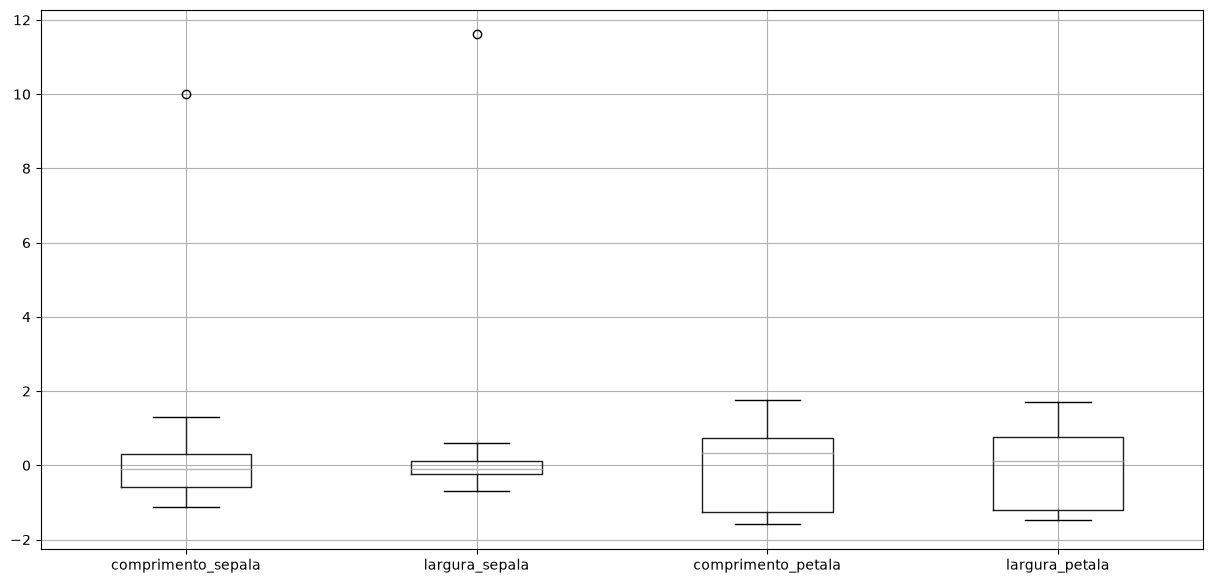

In [14]:
# gera um bloxplot para cada atributo
df.boxplot(figsize=(15,7))
plt.show()


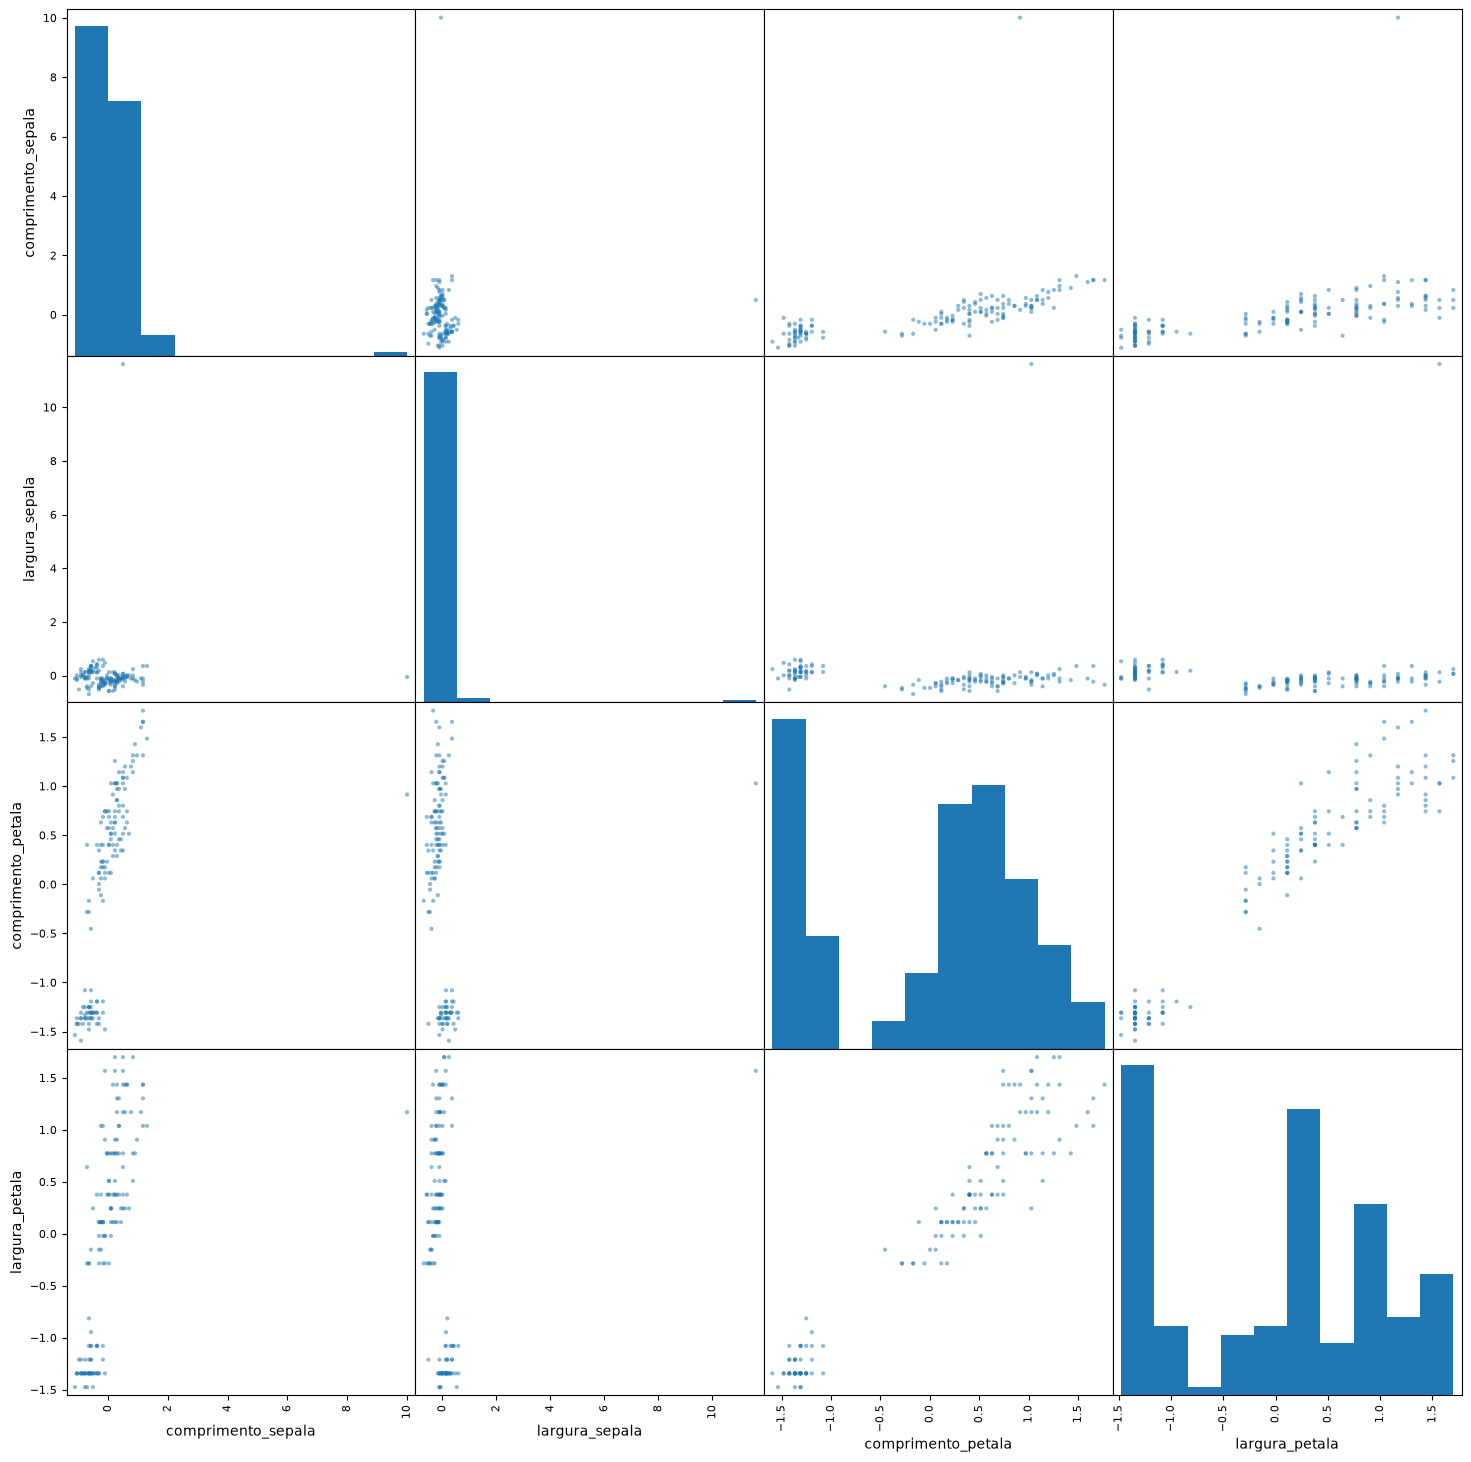

In [15]:
pd.plotting.scatter_matrix(df, figsize=(18,18))
plt.show()


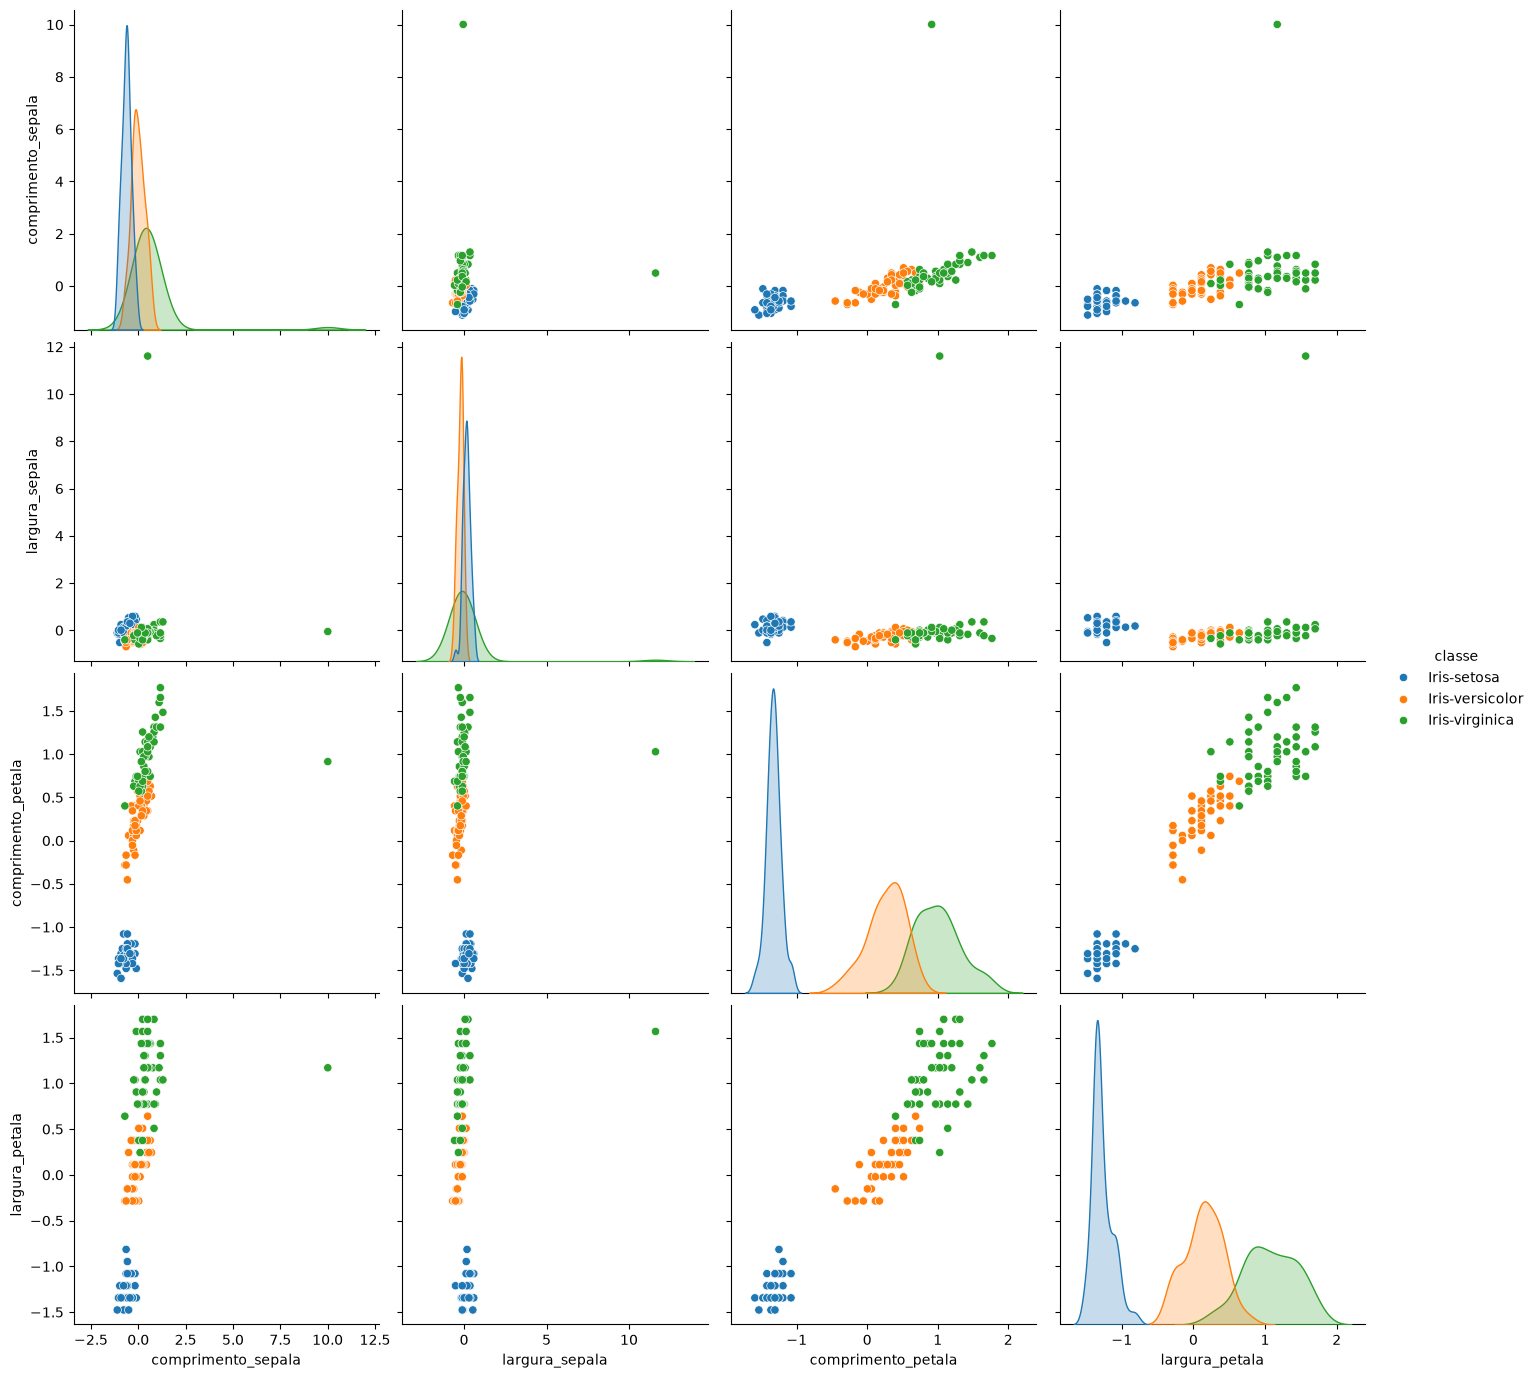

In [16]:
# matriz de gráficos scatter
sns.pairplot(df, hue='classe', height=3.5);

# mostra o gráfico usando a função show() da matplotlib
plt.show()


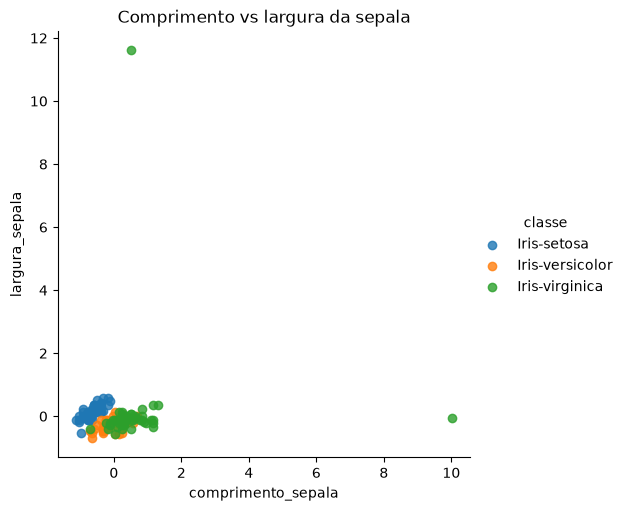

In [17]:
# define o scatter plot
sns.lmplot(x='comprimento_sepala', y='largura_sepala', data=df,
          fit_reg=False,
          hue='classe')

# cria um título para o gráfico
plt.title('Comprimento vs largura da sepala')

# mostra o gráfico
plt.show()


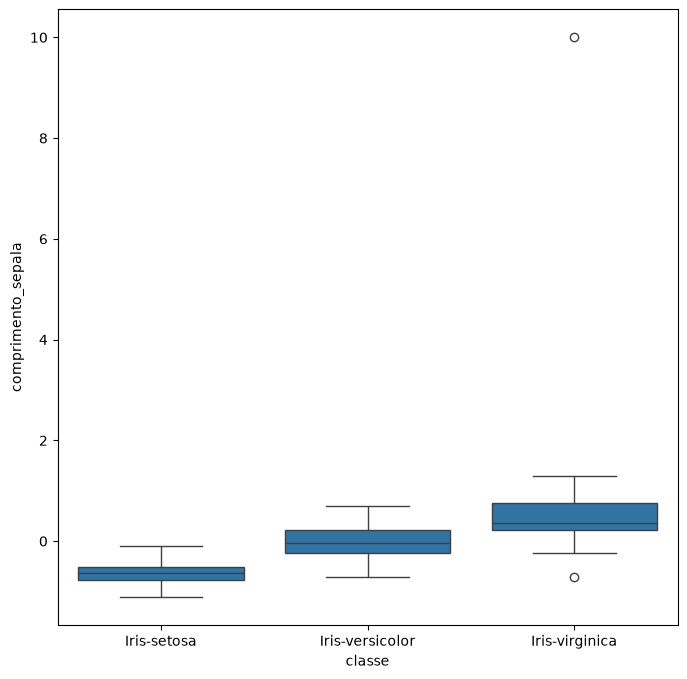

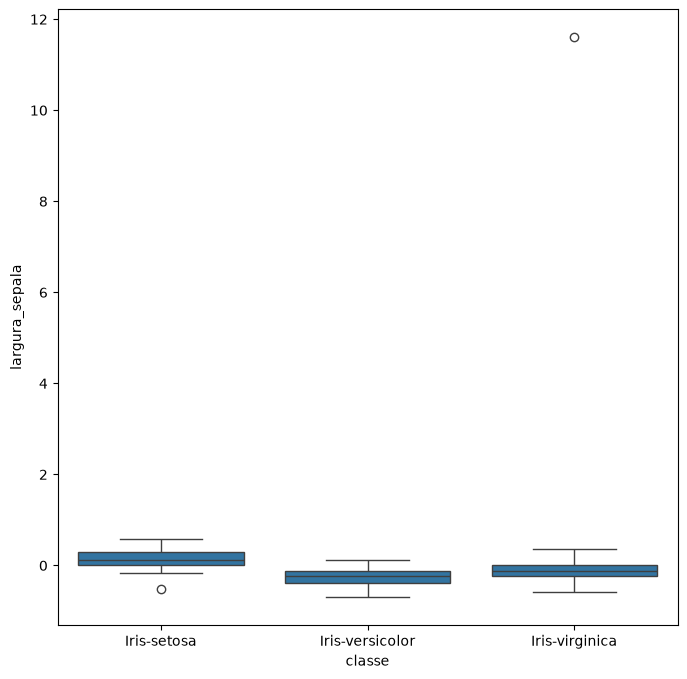

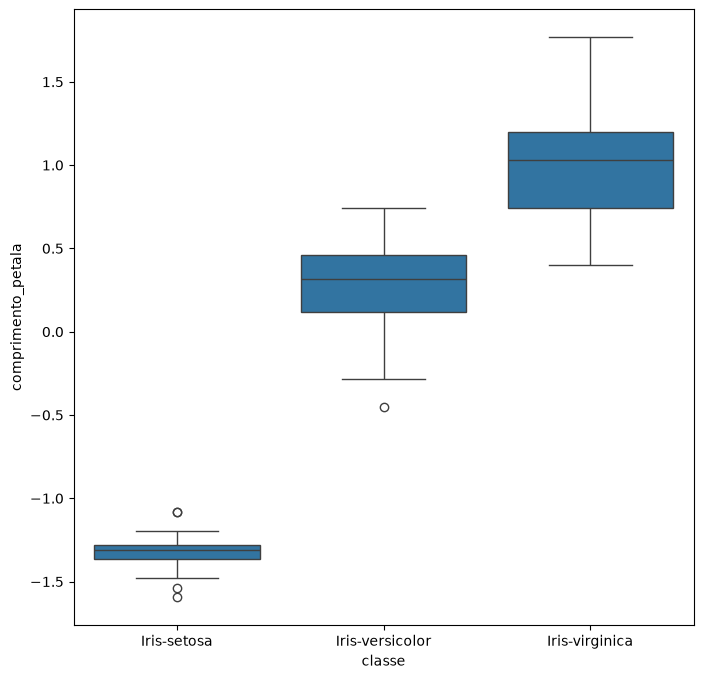

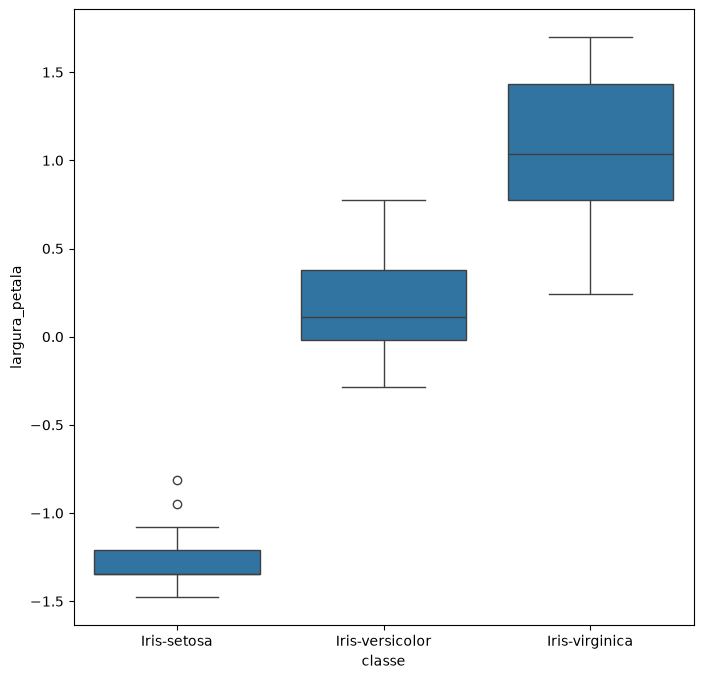

In [18]:
for atributo in df.columns[:-1]:
   # define a dimensão do gráfico
   plt.figure(figsize=(8,8))

   # cria o boxplot
   sns.boxplot(x="classe", y=atributo, data=df, whis=1.5)

   # mostra o gráfico
   plt.show()


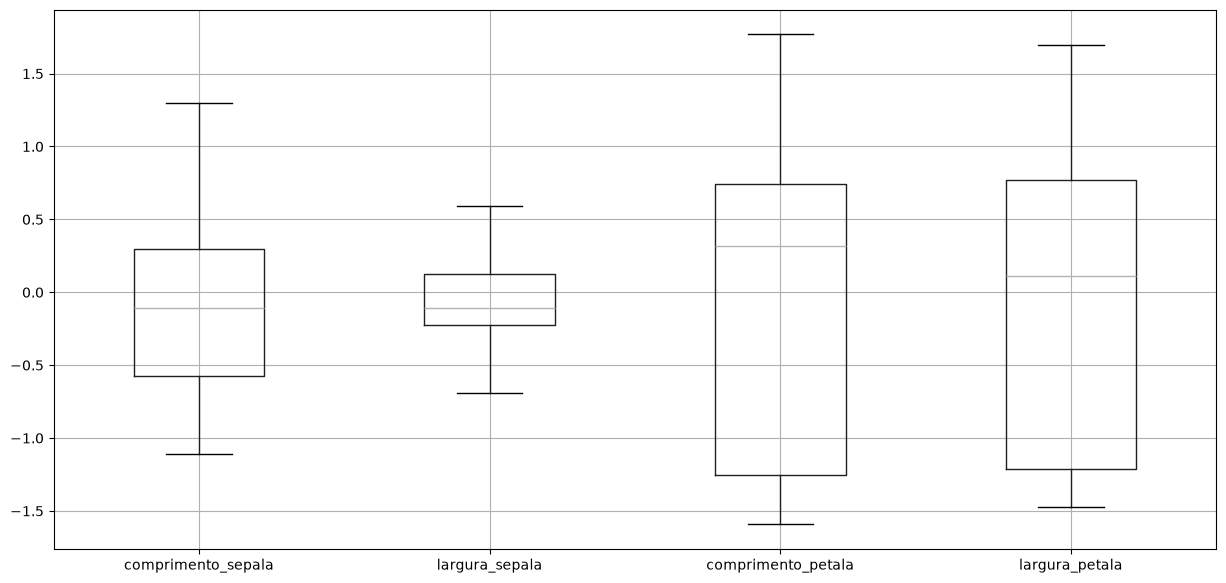

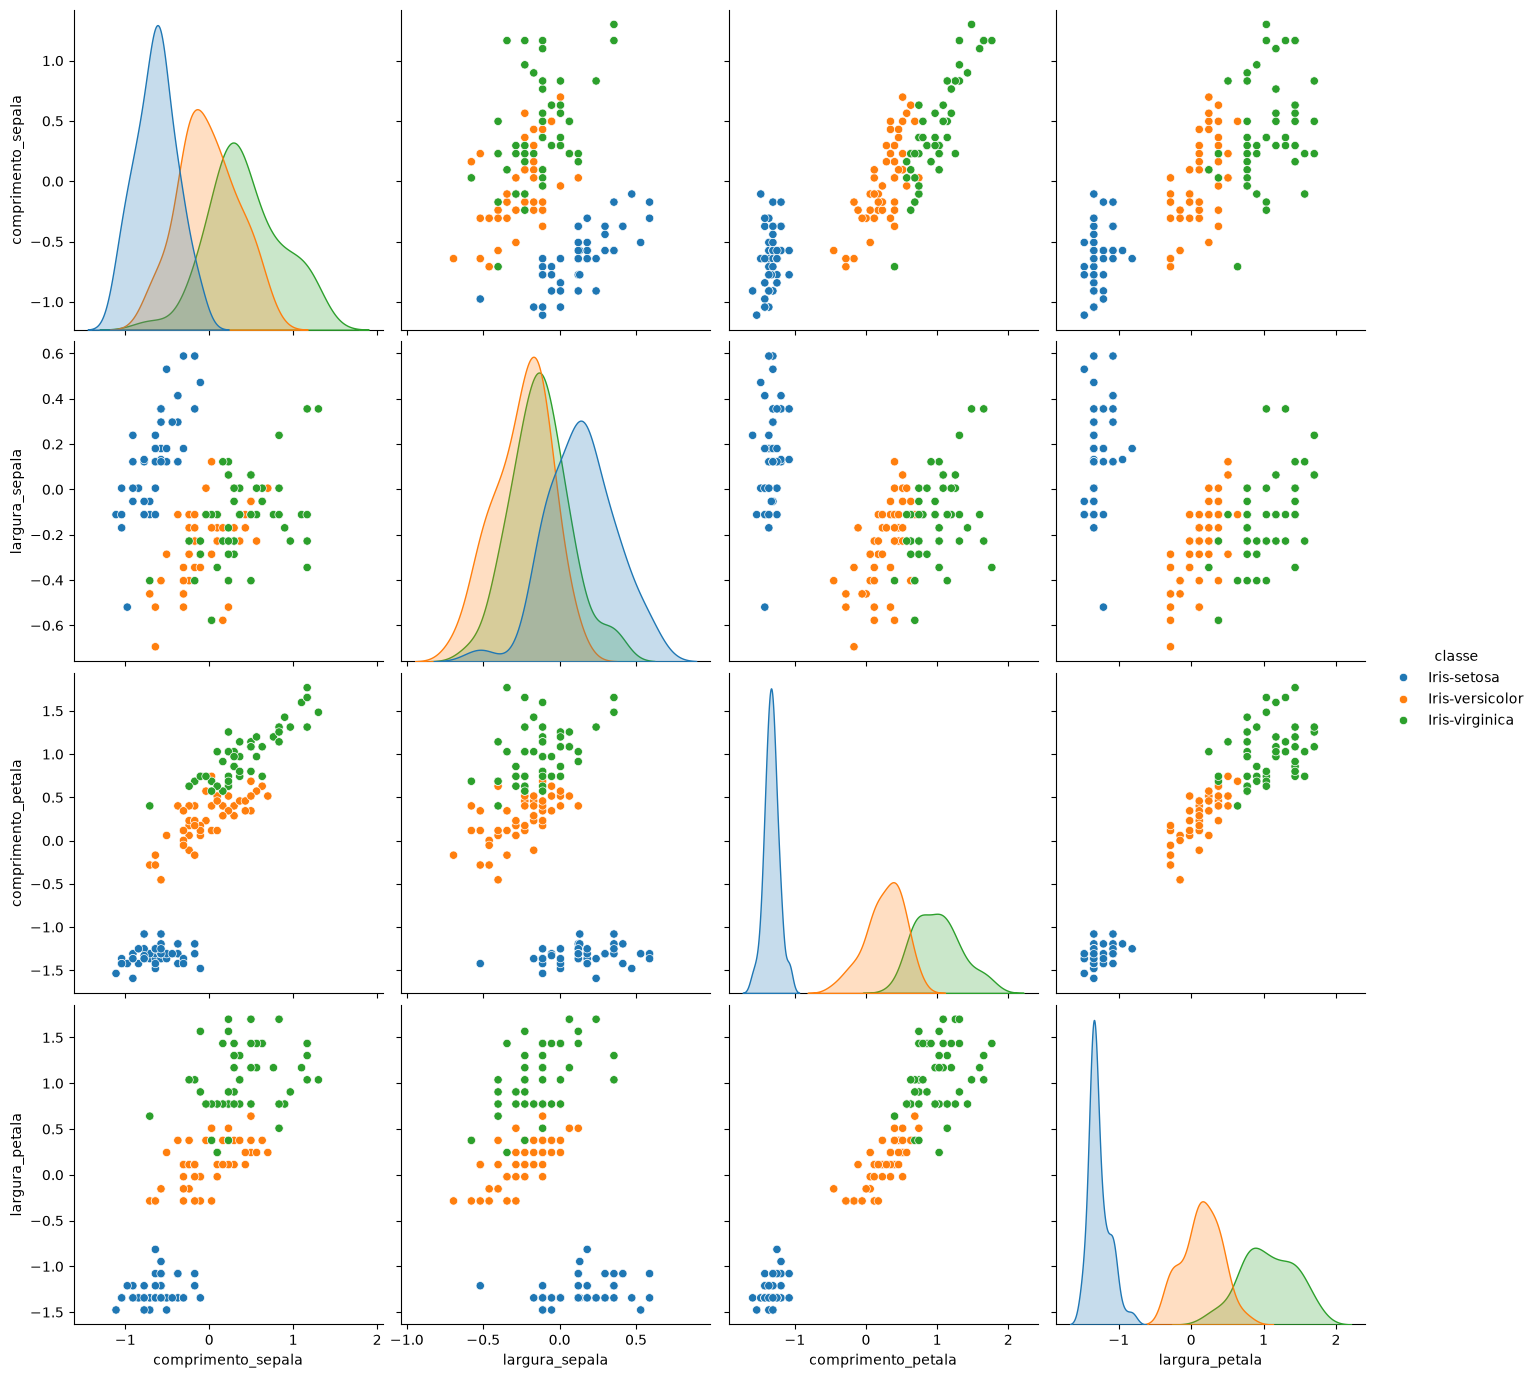

In [19]:
def removeOutliers(df):
   """
   Remove os outliers da base de dados
   """

   for atributo in df.columns[:-1]:

       # obtem o terceiro e o primeiro quartil.
       q75, q25 = np.percentile(df[atributo].values, [75 ,25])

       # calcula o IQR
       IQR = q75 - q25

       # remove os outliers com base no valor do IQR
       df = df[ (df[atributo]<=(q75+1.5*IQR)) & (df[atributo]>=(q25-1.5*IQR)) ]

   return df

# remove os outliers
df = removeOutliers(df)

# apresenta as principais estatísticas sobre a base de dados
df.boxplot(figsize=(15,7))
plt.show()

# matriz de gráficos scatter
sns.pairplot(df, hue='classe', height=3.5);

# mostra o gráfico usando a função show() da matplotlib
plt.show()



## Pré-processamento: distribuição das classes

classe
Iris-versicolor    50
Iris-setosa        47
Iris-virginica     47
Name: count, dtype: int64

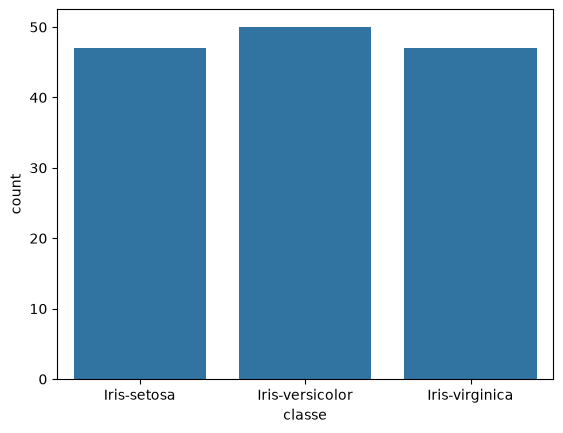

In [20]:
display(df['classe'].value_counts())

# cria um gráfico de barras com a frequência de cada classe
sns.countplot(x="classe", data=df)

# mostra o gráfico
plt.show()

## Pré-processamento: correlação entre os atributos

In [21]:
# criando uma matriz X com os valores do data frame
X = df.iloc[:,:-1].values

# matriz de correlação
correlation = np.corrcoef(X, rowvar=False)

print('\n\nMatriz de correlação: ')
display(correlation)



Matriz de correlação: 


array([[ 1.        , -0.11076465,  0.86879609,  0.81246161],
       [-0.11076465,  1.        , -0.42451388, -0.36208953],
       [ 0.86879609, -0.42451388,  1.        ,  0.96196534],
       [ 0.81246161, -0.36208953,  0.96196534,  1.        ]])

In [22]:
df_values = df.drop(columns=['classe'])

# matriz de correlação
df_correlation = df_values.corr()

print('\n\nMatriz de correlação: ')
display(df_correlation)



Matriz de correlação: 


,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala
comprimento_sepala,1.000000,-0.110765,0.868796,0.812462
largura_sepala,-0.110765,1.000000,-0.424514,-0.362090
comprimento_petala,0.868796,-0.424514,1.000000,0.961965
largura_petala,0.812462,-0.362090,0.961965,1.000000


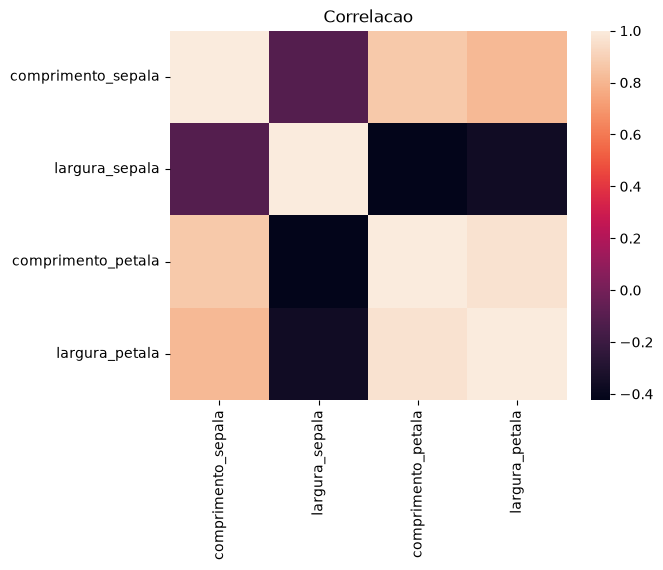

In [23]:
# cria um mapa de cores dos valores da correlação
sns.heatmap(df_correlation,
        xticklabels=df_correlation.columns,
        yticklabels=df_correlation.columns)

plt.title('Correlacao')
plt.show()

Lista de tarefas pendentes atualizada

Sim. Vou verificar a versão atual do notebook e recuperar as saídas das células executadas para explicar o fluxo e montar um relatório baseado nos resultados reais, não apenas no código. Também vou destacar o que cada etapa significa em termos de pré-processamento e aprendizado de máquina.



Retrieving Notebook summary.

O processamento terminou com sucesso: todas as 23 células de código foram executadas. Vou agora coletar as tabelas e mensagens principais, especialmente valores ausentes, duplicidades, normalização, distribuição das classes e correlações; os gráficos servirão como apoio visual à interpretação.

Read output of [](vscode-notebook-cell:/c%3A/Users/larin/Downloads/modeloAM/Pre_processamento.ipynb#W2sZmlsZQ%3D%3D)

Read output of [](vscode-notebook-cell:/c%3A/Users/larin/Downloads/modeloAM/Pre_processamento.ipynb#W4sZmlsZQ%3D%3D)

Read output of [](vscode-notebook-cell:/c%3A/Users/larin/Downloads/modeloAM/Pre_processamento.ipynb#W6sZmlsZQ%3D%3D)

Read output of [](vscode-notebook-cell:/c%3A/Users/larin/Downloads/modeloAM/Pre_processamento.ipynb#X10sZmlsZQ%3D%3D)

Read output of [](vscode-notebook-cell:/c%3A/Users/larin/Downloads/modeloAM/Pre_processamento.ipynb#X12sZmlsZQ%3D%3D)

Read output of [](vscode-notebook-cell:/c%3A/Users/larin/Downloads/modeloAM/Pre_processamento.ipynb#X13sZmlsZQ%3D%3D)

Read output of [](vscode-notebook-cell:/c%3A/Users/larin/Downloads/modeloAM/Pre_processamento.ipynb#X14sZmlsZQ%3D%3D)

Read output of [](vscode-notebook-cell:/c%3A/Users/larin/Downloads/modeloAM/Pre_processamento.ipynb#X15sZmlsZQ%3D%3D)

Read output of [](vscode-notebook-cell:/c%3A/Users/larin/Downloads/modeloAM/Pre_processamento.ipynb#X16sZmlsZQ%3D%3D)

Read output of [](vscode-notebook-cell:/c%3A/Users/larin/Downloads/modeloAM/Pre_processamento.ipynb#X21sZmlsZQ%3D%3D)

Read output of [](vscode-notebook-cell:/c%3A/Users/larin/Downloads/modeloAM/Pre_processamento.ipynb#X22sZmlsZQ%3D%3D)

Read output of [](vscode-notebook-cell:/c%3A/Users/larin/Downloads/modeloAM/Pre_processamento.ipynb#X34sZmlsZQ%3D%3D)
Completed with input: {
  "filePath": "c:\\Users\\larin\\Downloads\\modeloAM\\Pre_processamento.ipynb",
  "cellId": "#VSC-67958040"
}

Read output of [](vscode-notebook-cell:/c%3A/Users/larin/Downloads/modeloAM/Pre_processamento.ipynb#X36sZmlsZQ%3D%3D)

Read output of [](vscode-notebook-cell:/c%3A/Users/larin/Downloads/modeloAM/Pre_processamento.ipynb#X40sZmlsZQ%3D%3D)

Os resultados mostram um pipeline de preparação da base Iris, e não um classificador treinado: ao final, o notebook entrega dados limpos e padronizados para uma etapa posterior de aprendizado. Há dois pontos importantes para explicar no relatório: foram encontrados 3 valores ausentes, duplicidades e uma inconsistência de classe; além disso, a etapa de remoção de outliers eliminou mais 2 amostras.

Sim. O arquivo executado é um **modelo de pré-processamento**, não um modelo de classificação. Ele prepara os dados para que outro algoritmo, como KNN, árvore de decisão ou SVM, possa ser treinado depois.

## Relatório dos resultados

### 1. Objetivo

O notebook utiliza a base de flores Iris para:

- remover atributos que não ajudam na análise;
- tratar valores ausentes;
- remover dados duplicados ou inconsistentes;
- normalizar os atributos numéricos;
- investigar outliers;
- analisar a distribuição das classes;
- verificar correlações entre as variáveis.

A leitura e preparação inicial estão na primeira parte do `Pre_processamento.ipynb:8-38`.

### 2. Dados utilizados

Foram utilizadas quatro características numéricas:

- comprimento da sépala;
- largura da sépala;
- comprimento da pétala;
- largura da pétala.

A coluna `classe` é o resultado esperado, contendo:

- `Iris-setosa`;
- `Iris-versicolor`;
- `Iris-virginica`.

As colunas `id_planta` e `cidade_origem` foram removidas porque são identificadores ou informações administrativas, não características botânicas úteis para o modelo.

### 3. Valores ausentes

Foram encontrados três registros com valores ausentes:

- dois valores ausentes em `largura_sepala`;
- um valor ausente em `comprimento_petala`.

Todos pertenciam à classe `Iris-setosa`.

O notebook substituiu esses valores pela média da respectiva característica dentro da classe:

- `largura_sepala`: substituída por aproximadamente `3.416667`;
- `comprimento_petala`: substituído por aproximadamente `1.461224`.

A ideia é evitar a exclusão dessas linhas e manter a quantidade de amostras.

### 4. Dados duplicados e inconsistentes

Foram encontrados registros repetidos.

O notebook removeu duplicatas exatas, mantendo apenas a primeira ocorrência. Depois identificou uma inconsistência:

| Características | Classes diferentes |
|---|---|
| `5.0, 3.3, 1.4, 0.2` | `Iris-setosa` e `Iris-versicolor` |

Isso significa que duas flores possuem exatamente as mesmas medidas, mas foram registradas com classes diferentes. Como não é possível decidir automaticamente qual classificação está correta, as duas amostras foram removidas.

Depois dessas etapas, restaram **146 amostras**.

### 5. Estatísticas da base

Antes da normalização, as médias eram aproximadamente:

| Atributo | Média |
|---|---:|
| Comprimento da sépala | 5.958 |
| Largura da sépala | 3.191 |
| Comprimento da pétala | 3.796 |
| Largura da pétala | 1.216 |

As escalas são diferentes. Por exemplo, o comprimento da sépala varia em uma faixa diferente da largura da pétala. Por isso, foi feita a normalização.

### 6. Normalização

A função `normalizar` transforma cada característica usando o chamado **z-score**:

$$
z = \frac{x - \mu}{\sigma}
$$

onde:

- $x$ é o valor original;
- $\mu$ é a média da coluna;
- $\sigma$ é o desvio padrão da coluna.

Depois da normalização, cada atributo ficou com:

- média aproximadamente igual a `0`;
- desvio padrão igual a `1`.

A primeira amostra, originalmente:



In [ ]:
[5.1, 3.5, 1.4, 0.2]



passou a ser aproximadamente:



In [ ]:
[-0.5747, 0.1804, -1.3647, -1.3424]



A normalização é importante para algoritmos baseados em distância, pois impede que uma variável domine as outras apenas por ter valores numericamente maiores.

### 7. Outliers

O notebook utilizou boxplots e o intervalo interquartil, conhecido como IQR:

$$
IQR = Q_{75} - Q_{25}
$$

Um valor foi considerado outlier quando ficou fora do intervalo:

$$
[Q_{25} - 1.5 \times IQR,\ Q_{75} + 1.5 \times IQR]
$$

Foram identificadas medidas muito elevadas, principalmente nas características da sépala. Após a remoção dos outliers, a distribuição final das classes ficou:

| Classe | Quantidade |
|---|---:|
| `Iris-setosa` | 47 |
| `Iris-versicolor` | 50 |
| `Iris-virginica` | 47 |

Portanto, a base final possui **144 amostras**. As classes ficaram relativamente equilibradas.

### 8. Correlação entre atributos

Os principais resultados foram:

| Relação | Correlação |
|---|---:|
| Comprimento da sépala × comprimento da pétala | 0.869 |
| Comprimento da sépala × largura da pétala | 0.812 |
| Comprimento da pétala × largura da pétala | 0.962 |
| Largura da sépala × comprimento da pétala | -0.425 |

A maior correlação foi entre comprimento e largura da pétala:



In [ ]:
0.961965



Isso indica que flores com pétalas mais compridas tendem também a ter pétalas mais largas.

As características das pétalas provavelmente são as mais úteis para separar as espécies. A correlação, porém, não prova causalidade; ela apenas mostra que as variáveis variam de forma relacionada.

## O que este notebook ainda não faz

Apesar de ser chamado informalmente de “modelo”, ele ainda não:

- treina um algoritmo de classificação;
- divide os dados em treinamento e teste;
- prevê a classe de novas flores;
- calcula acurácia, precisão ou matriz de confusão.

Ele apenas prepara a base. Uma etapa posterior poderia usar, por exemplo:



In [ ]:
dados pré-processados
        ↓
divisão treino/teste
        ↓
treinamento de um classificador
        ↓
previsões
        ↓
avaliação da acurácia



## Observação importante sobre o código

A função de tratamento de valores ausentes calcula as médias apenas para `Iris-setosa`. Isso funcionou nesta execução porque todos os valores ausentes estavam nessa classe. Em uma base diferente, o ideal seria calcular a média separadamente para cada classe ou usar um método geral de imputação.

Em resumo: o notebook limpou a base, corrigiu valores ausentes, removeu registros problemáticos, padronizou as variáveis e fez uma análise exploratória. O próximo passo seria aplicar um algoritmo de classificação aos dados finais.

3 tarefas pendentes criadas